In [ ]:
# Arpit Huss (E23CSEU0554)

label
RESULTS        6522
METHODS        6409
CONCLUSIONS    3122
BACKGROUND     2389
OBJECTIVE      1558
Name: count, dtype: int64


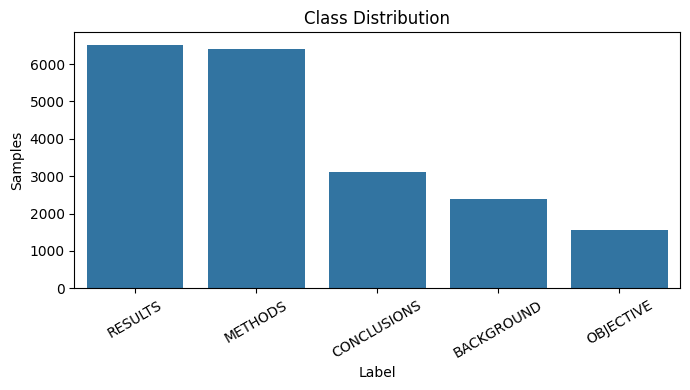

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | train_loss 0.7203 | train_acc 0.7252 | val_loss 0.4447 | val_acc 0.8407
Epoch 2/3 | train_loss 0.3868 | train_acc 0.8626 | val_loss 0.4247 | val_acc 0.8502
Epoch 3/3 | train_loss 0.2958 | train_acc 0.8960 | val_loss 0.4379 | val_acc 0.8522
Accuracy: 0.8522
Precision: 0.8535
Recall: 0.8522
F1-score: 0.8515
              precision    recall  f1-score   support

  BACKGROUND       0.66      0.77      0.71       478
 CONCLUSIONS       0.82      0.77      0.79       624
     METHODS       0.92      0.95      0.93      1282
   OBJECTIVE       0.72      0.58      0.64       312
     RESULTS       0.91      0.89      0.90      1304

    accuracy                           0.85      4000
   macro avg       0.81      0.79      0.80      4000
weighted avg       0.85      0.85      0.85      4000



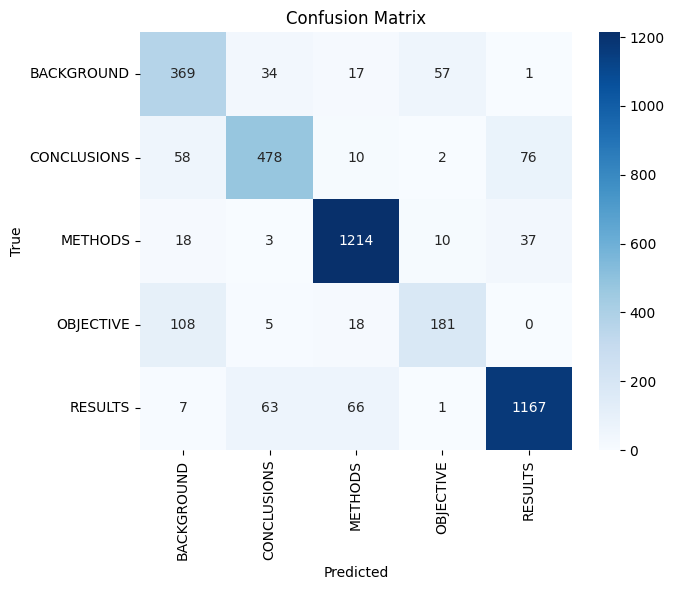

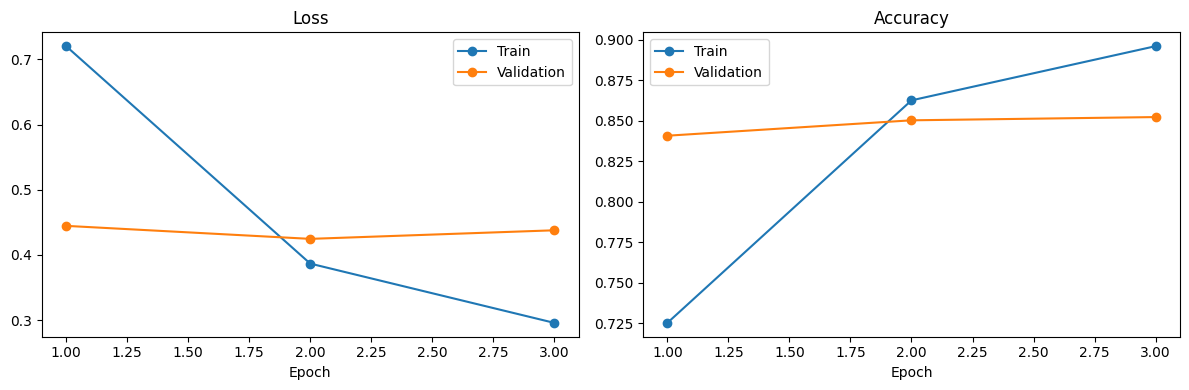

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/380 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  67%|██████▋   | 2/3 [00:00<?, ?it/s]

  0%|          | 0/306 [00:00<?, ?it/s]

PartitionExplainer explainer: 4it [00:19,  9.86s/it]

Text: neither gustation nor olfaction was significantly affected by the fluconazole treatment .
Predicted: RESULTS | True: RESULTS


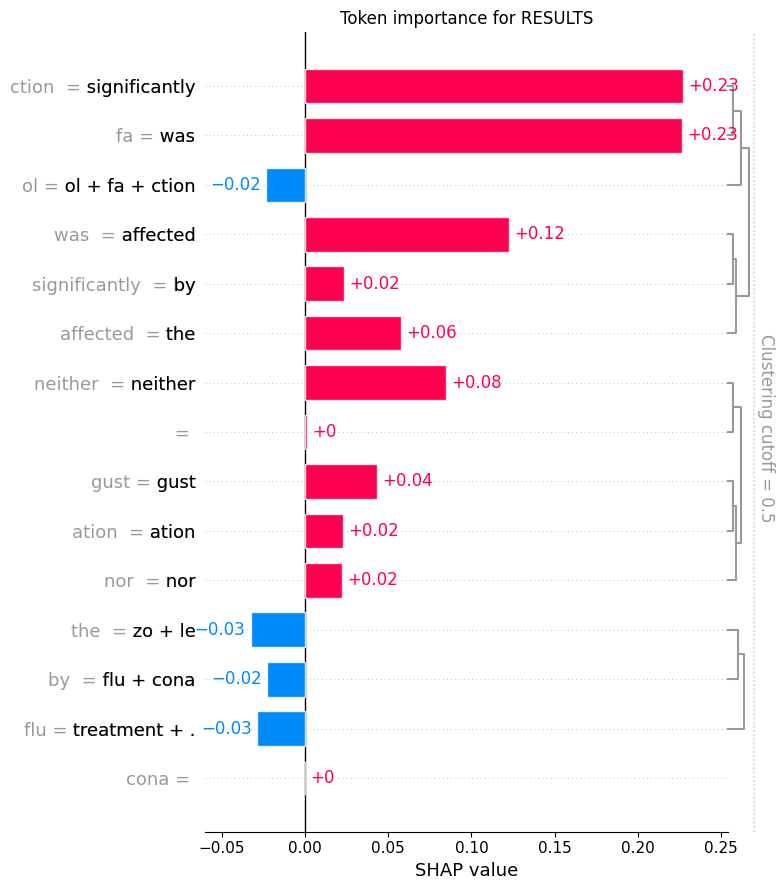

Text: further study of b cell-depleting therapies in myositis , particularly in treatment-nave patients , is warranted .
Predicted: CONCLUSIONS | True: CONCLUSIONS


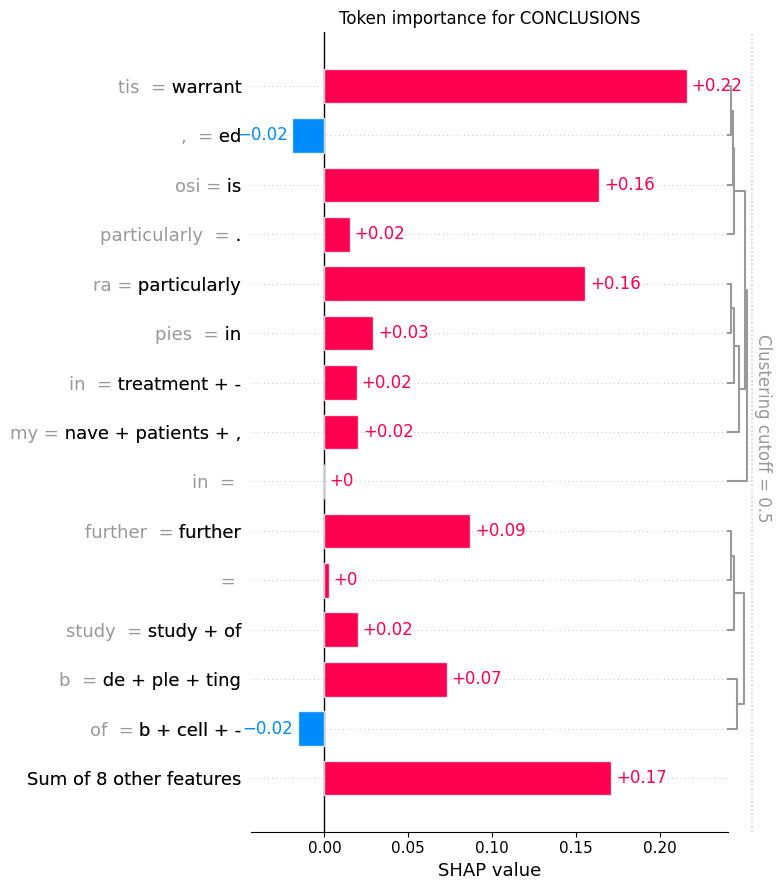

Text: students at high risk were successfully identified using personality indicators and reported poorer mental health .
Predicted: RESULTS | True: RESULTS


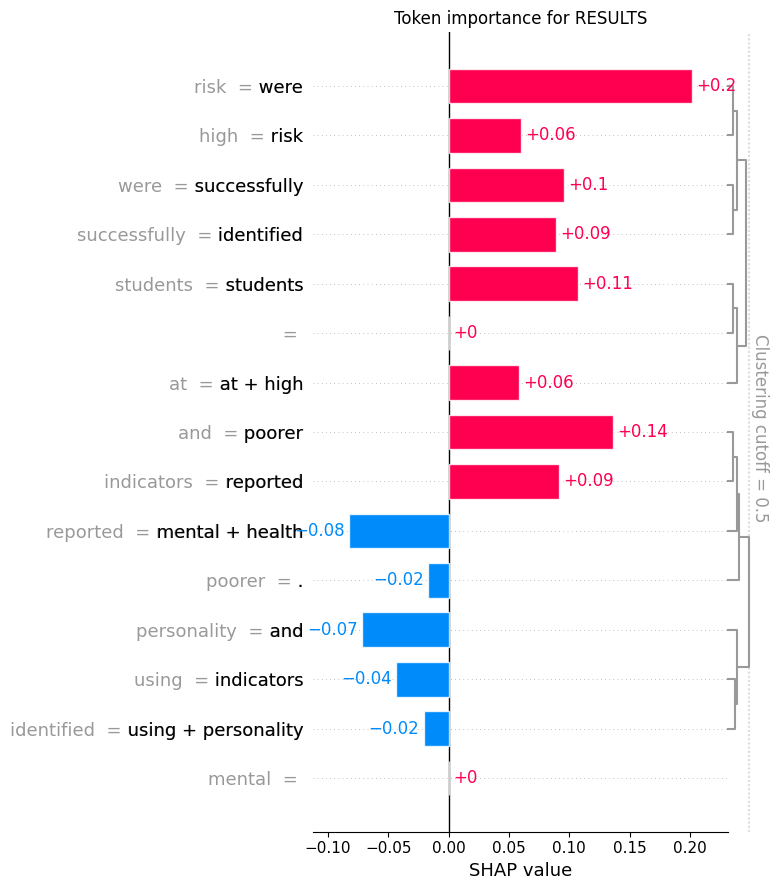

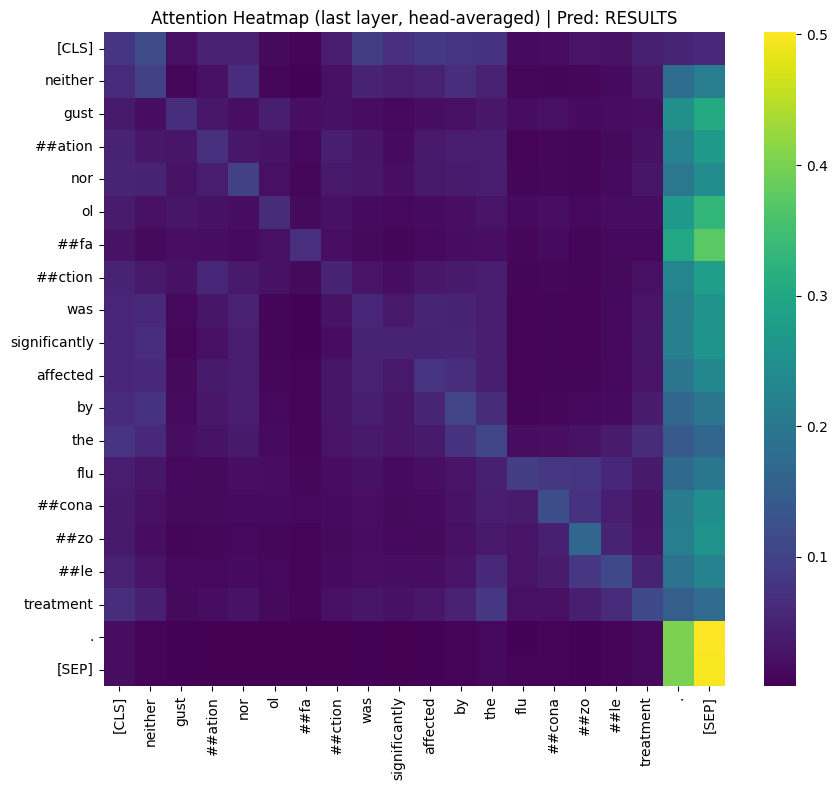

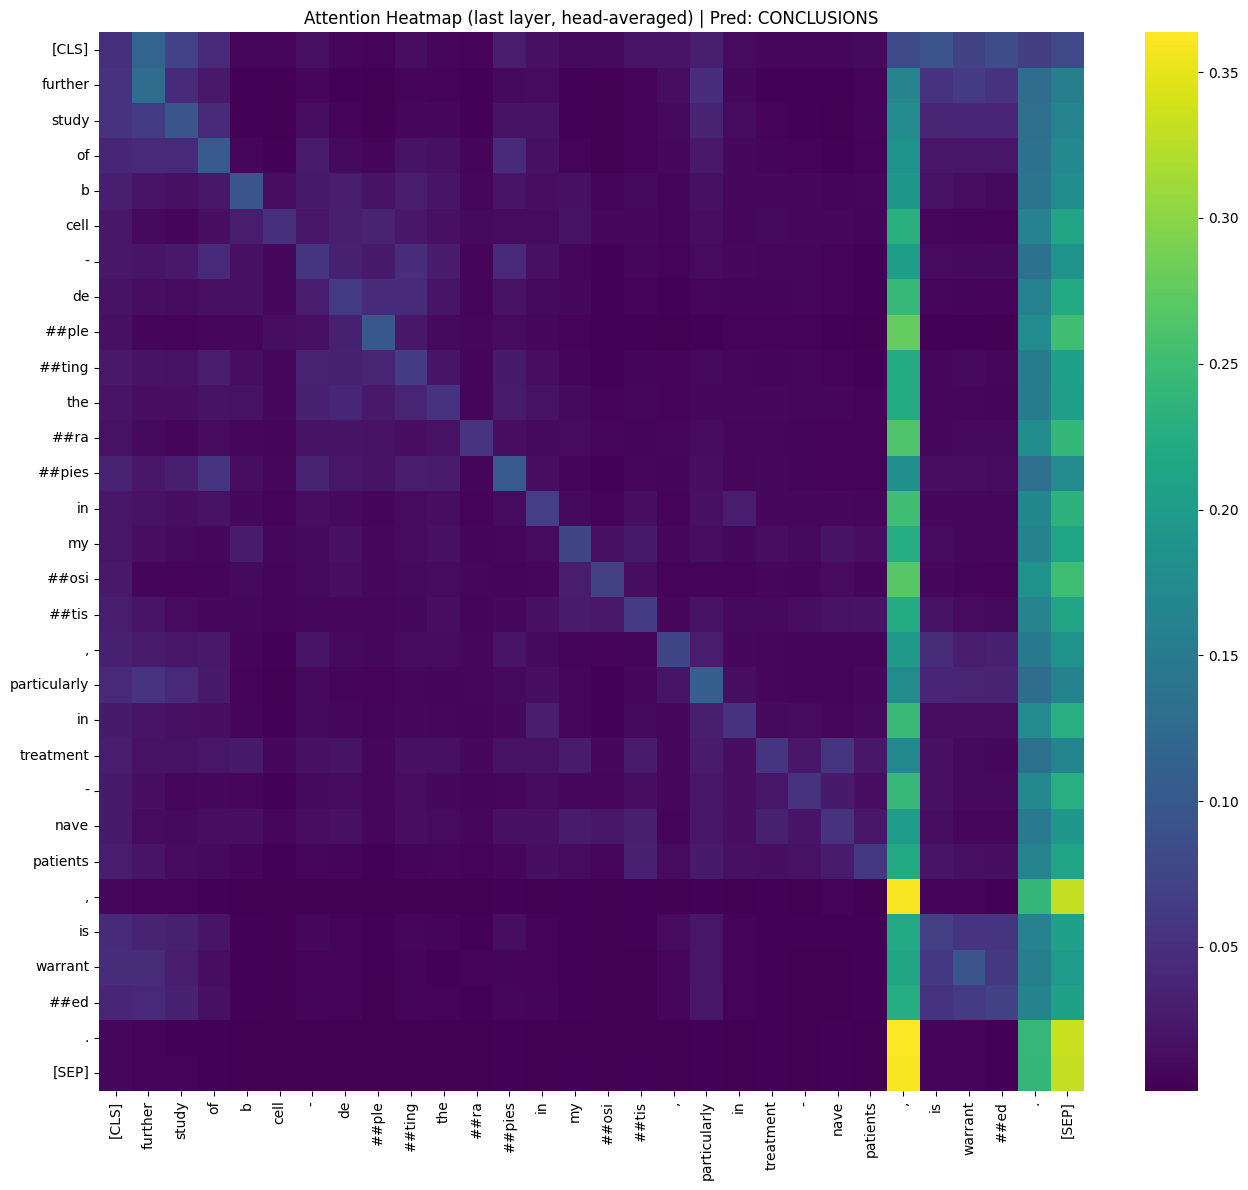

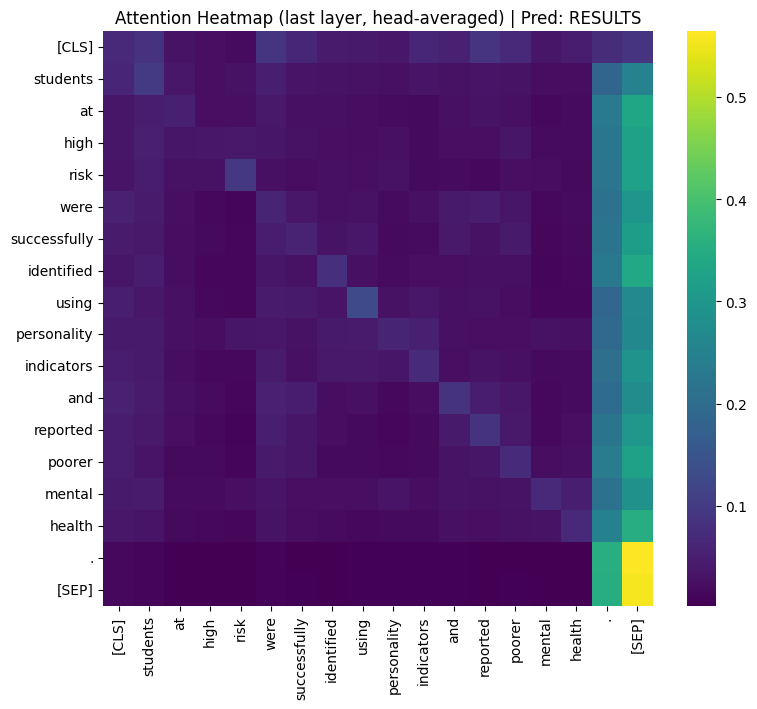

In [3]:
!pip install -q datasets transformers shap scikit-learn seaborn

import re
import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, ClassLabel
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, pipeline
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED = 42
SAMPLE = 20000
MAX_LEN = 64
BATCH = 32
EPOCHS = 3
LR = 2e-5
MODEL_NAME = "bert-base-uncased"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)

ds = load_dataset("ml4pubmed/pubmed-classification-20k", split="train")
df = ds.to_pandas()
df = df[["text", "label"]].dropna()
df["label"] = df["label"].astype(str)
df = df[~df["label"].str.startswith("###")].reset_index(drop=True)

df["text"] = df["text"].astype(str).str.lower().apply(lambda s: re.sub(r"\s+", " ", re.sub(r"[^a-z0-9\s\.\,\-%]", " ", s)).strip())
df = df[df["text"].str.len() > 0].drop_duplicates().reset_index(drop=True)
if len(df) > SAMPLE:
    df = df.sample(SAMPLE, random_state=SEED).reset_index(drop=True)

counts = df["label"].value_counts()
print(counts)
plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.xlabel("Label")
plt.ylabel("Samples")
plt.title("Class Distribution")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

classes = sorted(df["label"].unique())
c2i = {c: i for i, c in enumerate(classes)}
i2c = {i: c for c, i in c2i.items()}
df["y"] = df["label"].map(c2i)

train_df, val_df = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=SEED)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(frame):
    enc = tok(frame["text"].tolist(), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(frame["y"].values))

train_dl = DataLoader(encode(train_df), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(encode(val_df), batch_size=BATCH)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(classes), id2label=i2c, label2id=c2i, attn_implementation="eager"
).to(device)

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
criterion = torch.nn.CrossEntropyLoss()

def evaluate(loader):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    with torch.no_grad():
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            logits = model(input_ids=ids, attention_mask=mask).logits
            total_loss += criterion(logits, y).item() * y.size(0)
            preds.extend(logits.argmax(1).cpu().tolist())
            labels.extend(y.cpu().tolist())
    return total_loss / len(labels), accuracy_score(labels, preds), np.array(preds), np.array(labels)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, seen = 0.0, 0, 0
    for ids, mask, y in train_dl:
        ids, mask, y = ids.to(device), mask.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(input_ids=ids, attention_mask=mask).logits
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        seen += y.size(0)
    val_loss, val_acc, _, _ = evaluate(val_dl)
    history["train_loss"].append(running_loss / seen)
    history["train_acc"].append(correct / seen)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1}/{EPOCHS} | train_loss {history['train_loss'][-1]:.4f} | train_acc {history['train_acc'][-1]:.4f} | val_loss {val_loss:.4f} | val_acc {val_acc:.4f}")

_, acc, preds, labels = evaluate(val_dl)
prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
print(f"Accuracy: {acc:.4f}\nPrecision: {prec:.4f}\nRecall: {rec:.4f}\nF1-score: {f1:.4f}")
print(classification_report(labels, preds, target_names=classes, zero_division=0))

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

epochs_range = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs_range, history["train_loss"], marker="o", label="Train")
ax[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()
ax[1].plot(epochs_range, history["train_acc"], marker="o", label="Train")
ax[1].plot(epochs_range, history["val_acc"], marker="o", label="Validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()
plt.tight_layout()
plt.show()

model.eval()
pipe = pipeline("text-classification", model=model, tokenizer=tok, top_k=None, device=device, truncation=True, max_length=MAX_LEN)
samples = val_df["text"].iloc[:3].tolist()
explainer = shap.Explainer(pipe)
shap_values = explainer(samples)
for i, s in enumerate(samples):
    scores = pipe(s)[0]
    top = max(scores, key=lambda d: d["score"])["label"]
    print(f"Text: {s}\nPredicted: {top} | True: {val_df['label'].iloc[i]}")
    shap.plots.text(shap_values[i])
    plt.figure()
    shap.plots.bar(shap_values[i, :, top], max_display=15, show=False)
    plt.title(f"Token importance for {top}")
    plt.tight_layout()
    plt.show()

for s in val_df["text"].iloc[:3].tolist():
    enc = tok(s, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
    with torch.no_grad():
        out = model(**enc, output_attentions=True)
    att = out.attentions[-1][0].mean(0).cpu().numpy()
    tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
    plt.figure(figsize=(max(6, len(tokens) * 0.45), max(5, len(tokens) * 0.4)))
    sns.heatmap(att, xticklabels=tokens, yticklabels=tokens, cmap="viridis")
    plt.title(f"Attention Heatmap (last layer, head-averaged) | Pred: {i2c[out.logits.argmax(1).item()]}")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()